# CG · Де на мапі дим, якщо камера бачить лише напрямок?

**Тип:** сценарний аналіз. **Навіщо:** Наскільки точно можна знайти місце диму за напрямком і рельєфом і що дає друга камера.

Цей ноутбук повторює блок сторінки досліджень `web/science/#cg` і бере ті самі результати.

In [1]:
import sys
sys.path.insert(0, '..')
import pandas as pd
from eaglewings.ds import report
pd.set_option('display.width', 200)
%matplotlib inline

## Постановка, дані, протокол і метрики

Текст узято з модуля задачі, той самий записується в журнал кожного запуску.

In [2]:
print(report.protocol('CG'))

CG · Камера на координати: наскільки точно можна вказати місце диму на мапі.

Задача      камера дає лише напрямок. Зона на мапі це клин, звужений прямою видимістю по рельєфу.
Дані        реальні гекси з точками NASA FIRMS у парку: пожежі 2022 (валідація) і 2023 (тест), рельєф SRTM.
Протокол    місце пожежі реальне, а напрямок симульований: справжній азимут плюс похибка з відхиленням 1, 3, 5, 10°.
            Ширину клина (1, 2 або 3 відхилення) обираємо на 2022: найменша зона, що накриває місце в ≥ 90 % випадків.
Метрики     влучання: справжній гекс у зоні; площа зони; відстань від місця до центру зони.
Підходи
  wedge      клин без рельєфу, одна камера: базова лінія
  wedge_los  клин і пряма видимість, одна камера
  two_cams   перетин двох клинів із прямою видимістю
Окремо      яку частку гексів із пожежами бачить кожна камера за різної висоти щогли й дальності.
Обмеження   справжніх детекцій диму з координатами немає, тому це перевірка геометрії, а не детектора.



## Результат

Обраний підхід виділено. Вибір робився лише на валідації, числа тут з тесту.

,approach,sigma,k,val_hit,test_hit,test_km2,test_km,n
0,wedge,1.0,2.0,0.979,0.945,2.933,1.798,948
1,wedge_los,1.0,2.0,0.979,0.945,1.525,1.319,948
2,two_cams,1.0,2.0,0.981,0.918,0.117,0.000,207
3,wedge,3.0,2.0,0.979,0.945,8.447,1.788,948
4,wedge_los,3.0,2.0,0.979,0.945,4.341,1.407,948
5,two_cams,3.0,2.0,0.981,0.918,0.704,0.302,207
6,wedge,5.0,2.0,0.979,0.945,13.961,1.835,948
7,wedge_los,5.0,2.0,0.979,0.945,7.156,1.503,948
8,two_cams,5.0,2.0,0.981,0.918,1.291,0.465,207
9,wedge,10.0,2.0,0.979,0.945,27.394,2.100,948


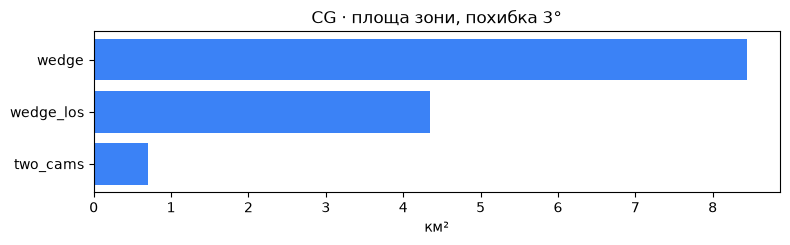

In [3]:
table, fig = report.show('CG')
table